In [2]:
import requests
import numpy as np
from sympy import *

headers = {
    'token': 'b2346f3e0fdfc55e2199316ac4bd8feb'
}                 

In [3]:
def getHeightForPoint(longitude,latitude):
    height_model_response =  requests.get(f"https://services.datafordeler.dk/DHMTerraen/DHMKoter/1.0.0/GEOREST/HentKoter?username={user}&password={password}&geop=POINT({longitude}%20{latitude})")

    return height_model_response.json()["HentKoterRespons"]["data"][0]["kote"]

In [4]:
item = requests.get('https://api.dataforsyningen.dk/rest/skraafoto_api/v1.0/collections/skraafotos2023/items/2023_82_23_2_0012_00001362', headers=headers)

In [11]:
item.json()

{'type': 'Feature',
 'stac_version': '1.0.0',
 'stac_extensions': ['https://stac-extensions.github.io/view/v1.0.0/schema.json',
  'https://stac-extensions.github.io/projection/v1.0.0/schema.json',
  'https://raw.githubusercontent.com/stac-extensions/perspective-imagery/main/json-schema/schema.json'],
 'id': '2023_82_23_2_0012_00001362',
 'collection': 'skraafotos2023',
 'geometry': {'type': 'Polygon',
  'coordinates': [[[9.828368773330094, 55.8696539661694],
    [9.853499831474384, 55.869338962728],
    [9.849764311824739, 55.85661670314353],
    [9.831549785620979, 55.85675351843603],
    [9.828368773330094, 55.8696539661694]]]},
 'bbox': [9.828368773330094,
  55.85661670314353,
  9.853499831474384,
  55.8696539661694],
 'properties': {'datetime': '2023-04-08T13:44:42Z',
  'gsd': 0.09,
  'license': 'various',
  'platform': 'Fixed-wing aircraft',
  'instruments': ['Osprey-434S42218X318205-f120_Rev01.00_C114'],
  'providers': [{'name': 'field', 'roles': ['producer']},
   {'url': 'https:

In [12]:
## from skraafoto 

item = item.json()
props = item["properties"]
m11, m12, m13, m21, m22, m23, m31, m32, m33 = props["pers:rotation_matrix"]
Xc, Yc, Zc = props["pers:perspective_center"] ## camera position 
f_mm = props["pers:interior_orientation"]["focal_length"]
ppo_x, ppo_y = props["pers:interior_orientation"]["principal_point_offset"]
pixel_size = props["pers:interior_orientation"]["pixel_spacing"][0]
sensor_cols, sensor_rows = props["pers:interior_orientation"]["sensor_array_dimensions"]

## for coordinate conversion
crs = props["pers:crs"]
vertical_crs = props["pers:vertical_crs"]
image_url = props["asset:data"]

# Calculated values. In pixels. Origo in image lower left.
f = f_mm / pixel_size
x0 = sensor_cols * 0.5 + ppo_x / pixel_size
y0 = sensor_rows * 0.5 + ppo_y / pixel_size

In [67]:
f,x0, y0, crs, vertical_crs, image_url

(32813.82978723404,
 7072.0,
 5280.0,
 25832,
 5799,
 'https://cdn.dataforsyningen.dk/skraafoto_server/COG_oblique_2023/10km_619_55/1km_6191_552/2023_82_23_2_0012_00001362.tif')

In [ ]:
## around via 
## latitude = 55, 51, 47.8, 'N'
## longitude = 9, 50, 13.5, 'E'

import math

## chat gpt to get lat long

def dms_to_decimal(degrees, minutes, seconds, direction):
    decimal = degrees + minutes / 60 + seconds / 3600
    if direction in ['S', 'W']:
        decimal *= -1  # South and West are negative
    return decimal

# Convert latitude and longitude to decimal degrees
latitude = dms_to_decimal(55, 51, 47.8, 'N')
longitude = dms_to_decimal(9, 50, 13.5, 'E')
print("Decimal Degrees:", latitude, longitude)


Decimal Degrees: 55.86327777777778 9.837083333333334


In [9]:
from pyproj import Transformer

transformer = Transformer.from_crs("EPSG:4326", "EPSG:" + str(crs), always_xy=True)

# Transform latitude and longitude to UTM coordinates in EPSG:25832
x, y = transformer.transform(longitude, latitude)
z = getHeightForPoint(x, y)
print("UTM Coordinates (X, Y):", x, y, z)



NameError: name 'crs' is not defined

In [106]:
# rotation matrix
R = Matrix([[m11, m12, m13],
              [m21, m22, m23],
              [m31, m32, m33]])

# camera positiom 
C = Matrix([Xc, Yc, Zc])

K = Matrix([[-f, 0, x0,], [0,-f,y0], [0,0,1]]) 

I = eye(3)

translation = Matrix([[-Xc], [-Yc], [-Zc]])

T = Matrix.hstack(I, translation)

In [107]:
K


Matrix([
[-32813.829787234,                0, 7072.0],
[               0, -32813.829787234, 5280.0],
[               0,                0,      1]])

In [108]:
R

Matrix([
[    0.999999127862303, -0.0013205618332865, 1.97756627126463e-5],
[  0.00091804264379875,   0.705798947552479,   0.708411605517243],
[-0.000949458970433025,  -0.708410969529875,   0.705799544330687]])

In [109]:
C

Matrix([
[ 552620.958],
[6188874.896],
[    2172.74]])

In [110]:
T

Matrix([
[1, 0, 0,  -552620.958],
[0, 1, 0, -6188874.896],
[0, 0, 1,     -2172.74]])

In [111]:
KRT = K * R * T 
KRT

Matrix([
[     -32820.515742895,   -4966.5496852943,  4990.76546227643, 48863815883.1968],
[    -35.1376384149209,  -26900.3764481137,  -19519.076248678, 166544892165.812],
[-0.000949458970433025, -0.708410969529875, 0.705799544330687, 4383258.03739834]])

In [112]:
point_3D = Matrix([x, y, z, 1]) ## around VIA in Horsens
point_3D 

Matrix([
[552390.526564775],
[6191179.72188173],
[       2.1319776],
[               1]])

In [113]:
mapping = KRT * point_3D
mapping

Matrix([
[-14717149.2604446],
[-19624323.5541992],
[ -3164.5593054099]])

In [114]:
pixel_x = mapping[0]/mapping[2]
pixel_y = mapping[1]/mapping[2]

In [115]:
pixel_x, pixel_y

(4650.61572247525, 6201.28165101880)

In [116]:
projected_2D_point_final = Matrix([[pixel_x],[pixel_y]])

In [117]:
projected_2D_point_final

Matrix([
[4650.61572247525],
[ 6201.2816510188]])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/PIL/Image.py:3368: DecompressionBombWarning: Image size (149360640 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


NameError: name 'projected_2D_point_final' is not defined

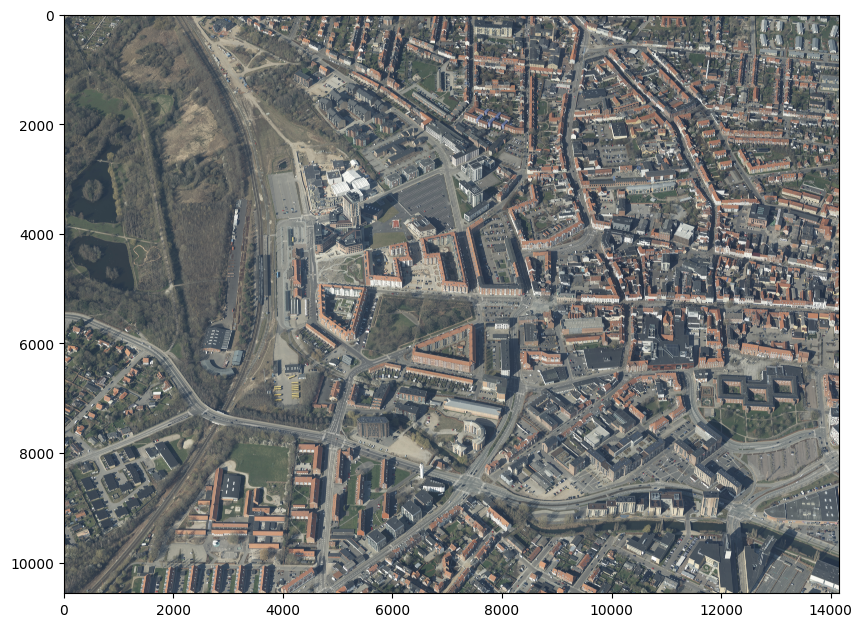

In [18]:
from PIL import Image
import matplotlib.pyplot as plt

## again chat gpt 


response = requests.get(image_url)
with open("skraafoto_image.tif", "wb") as f:
    f.write(response.content)

# Open the image
image = Image.open("skraafoto_image.tif")

# Display the image with matplotlib
plt.figure(figsize=(10, 10))
plt.imshow(image)


pixel_x = projected_2D_point_final[0]  
pixel_y = image.height - projected_2D_point_final[1]  

# Plot the pixel as a red dot
plt.plot(pixel_x, pixel_y, 'ro', markersize=5, label='Calculated Pixel')
plt.legend()
plt.title("Skraafoto Image with Calculated Pixel Overlay")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.show()

UTM Coordinates (X, Y): 6314681.044675703 1640585.8482629883 10


In [119]:
item2 = requests.get('https://api.dataforsyningen.dk/rest/skraafoto_api/v1.0/collections/skraafotos2023/items/2023_82_24_2_0010_00000350', headers=headers)
item2.json()

{'type': 'Feature',
 'stac_version': '1.0.0',
 'stac_extensions': ['https://stac-extensions.github.io/view/v1.0.0/schema.json',
  'https://stac-extensions.github.io/projection/v1.0.0/schema.json',
  'https://raw.githubusercontent.com/stac-extensions/perspective-imagery/main/json-schema/schema.json'],
 'id': '2023_82_24_2_0010_00000350',
 'collection': 'skraafotos2023',
 'geometry': {'type': 'Polygon',
  'coordinates': [[[10.16402833901744, 56.15778601402202],
    [10.189014745634223, 56.15759236781892],
    [10.184977878826855, 56.14491636562711],
    [10.166871531628622, 56.14519559719203],
    [10.16402833901744, 56.15778601402202]]]},
 'bbox': [10.16402833901744,
  56.14491636562711,
  10.189014745634223,
  56.15778601402202],
 'properties': {'datetime': '2023-04-18T09:34:22Z',
  'gsd': 0.09,
  'license': 'various',
  'platform': 'Fixed-wing aircraft',
  'instruments': ['Osprey-434S42218X318205-f120_Rev01.00_C117'],
  'providers': [{'name': 'field', 'roles': ['producer']},
   {'url'

In [120]:
data = item2.json()
props = data["properties"]
m11, m12, m13, m21, m22, m23, m31, m32, m33 = props["pers:rotation_matrix"]
Xc, Yc, Zc = props["pers:perspective_center"] ## camera position 
f_mm = props["pers:interior_orientation"]["focal_length"]
ppo_x, ppo_y = props["pers:interior_orientation"]["principal_point_offset"]
pixel_size = props["pers:interior_orientation"]["pixel_spacing"][0]
sensor_cols, sensor_rows = props["pers:interior_orientation"]["sensor_array_dimensions"]

## for coordinate conversion
crs = props["pers:crs"]
vertical_crs = props["pers:vertical_crs"]
image_url = props["asset:data"]

# Calculated values. In pixels. Origo in image lower left.
f = f_mm / pixel_size
x0 = sensor_cols * 0.5 + ppo_x / pixel_size
y0 = sensor_rows * 0.5 + ppo_y / pixel_size

In [121]:
## systematic 56.152247, 10.177252
latitude = 56.152247
longitude = 10.177252

transformer = Transformer.from_crs("EPSG:4326", "EPSG:" + str(crs), always_xy=True)

x, y = transformer.transform(longitude, latitude)
z = getHeightForPoint(x,y)
print("UTM Coordinates (X, Y):", x, y, z)

UTM Coordinates (X, Y): 573131.7837502563 6223648.495853622 2.7803061


In [122]:
# rotation matrix
R = Matrix([[m11, m12, m13],
              [m21, m22, m23],
              [m31, m32, m33]])

# camera positiom 
C = Matrix([Xc, Yc, Zc])

K = Matrix([[-f, 0, x0,], [0,-f,y0], [0,0,1]]) 

I = eye(3)

translation = Matrix([[-Xc], [-Yc], [-Zc]])

T = Matrix.hstack(I, translation)

In [123]:
KRT = K * R * T 
KRT

Matrix([
[   -32851.9617541056,  -4754.00477847911,   4990.8573189934, 48391185525.7789],
[   -187.996077887372,   -26959.766303764, -19436.0871480526, 167874459181.106],
[-0.00551695777872606, -0.706211841574838, 0.707979094321536, 4395190.44515063]])

In [124]:
point_3D = Matrix([x, y, z, 1]) ## systematic aarhus
point_3D 

Matrix([
[573131.783750256],
[6223648.49585362],
[       2.7803061],
[               1]])

In [125]:
mapping = KRT * point_3D
mapping

Matrix([
[ -24558726.798233],
[-21450389.6099548],
[-3183.79587463196]])

In [126]:
pixel_x = mapping[0]/mapping[2]
pixel_y = mapping[1]/mapping[2]

pixel_x, pixel_y

(7713.66248505864, 6737.36334068038)

In [127]:
projected_2D_point_final = Matrix([[pixel_x],[pixel_y]])
projected_2D_point_final

Matrix([
[7713.66248505864],
[6737.36334068038]])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/PIL/Image.py:3368: DecompressionBombWarning: Image size (149360640 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


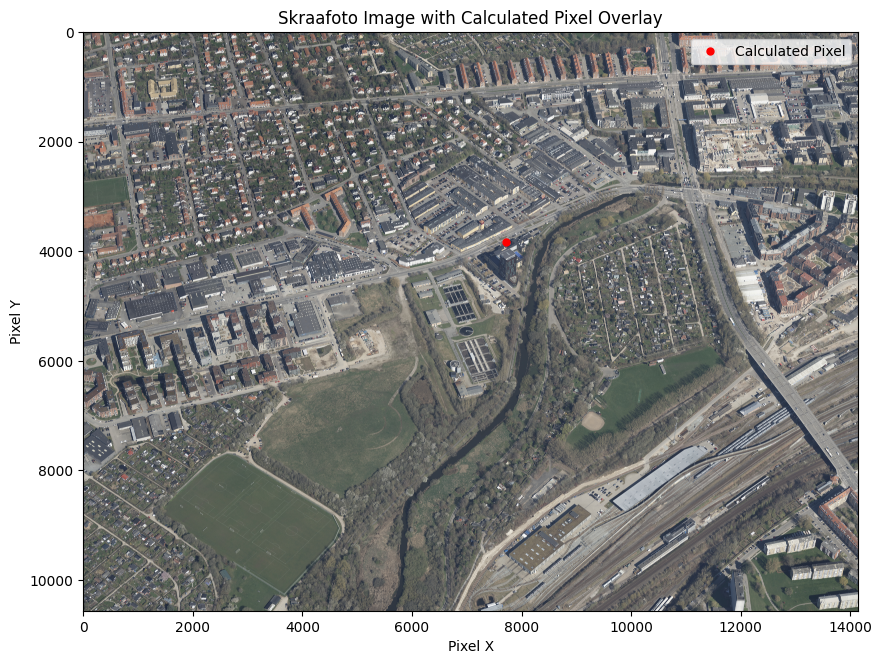

In [129]:
response = requests.get(image_url)
with open("skraafoto_image.tif", "wb") as f:
    f.write(response.content)

# Open the image
image = Image.open("skraafoto_image.tif")

# Display the image with matplotlib
plt.figure(figsize=(10, 10))
plt.imshow(image)


pixel_x = projected_2D_point_final[0]  
pixel_y = image.height - projected_2D_point_final[1]  

# Plot the pixel as a red dot
plt.plot(pixel_x, pixel_y, 'ro', markersize=5, label='Calculated Pixel')
plt.legend()
plt.title("Skraafoto Image with Calculated Pixel Overlay")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.show()

In [116]:
## 55.67284925837159, 12.568741989862998
## Tivoli Copenhagen 

In [130]:
item3 = requests.get('https://api.dataforsyningen.dk/rest/skraafoto_api/v1.0/collections/skraafotos2023/items/2023_84_40_2_0142_00114710', headers=headers)
item3.json()

{'type': 'Feature',
 'stac_version': '1.0.0',
 'stac_extensions': ['https://stac-extensions.github.io/view/v1.0.0/schema.json',
  'https://stac-extensions.github.io/projection/v1.0.0/schema.json',
  'https://raw.githubusercontent.com/stac-extensions/perspective-imagery/main/json-schema/schema.json'],
 'id': '2023_84_40_2_0142_00114710',
 'collection': 'skraafotos2023',
 'geometry': {'type': 'Polygon',
  'coordinates': [[[12.559225222688744, 55.678255991454435],
    [12.578460598447503, 55.67764619807722],
    [12.57468445216211, 55.66800801105784],
    [12.561226836337156, 55.66840664879663],
    [12.559225222688744, 55.678255991454435]]]},
 'bbox': [12.559225222688744,
  55.66800801105784,
  12.578460598447503,
  55.678255991454435],
 'properties': {'datetime': '2023-05-08T11:47:10Z',
  'gsd': 0.1,
  'license': 'various',
  'platform': 'Fixed-wing aircraft',
  'instruments': ['CityMapper2_96773_S150161-112088'],
  'providers': [{'name': 'leica', 'roles': ['producer']},
   {'url': 'htt

In [142]:
data = item3.json()
props = data["properties"]
m11, m12, m13, m21, m22, m23, m31, m32, m33 = props["pers:rotation_matrix"]
Xc, Yc, Zc = props["pers:perspective_center"] ## camera position 
f_mm = props["pers:interior_orientation"]["focal_length"]
ppo_x, ppo_y = props["pers:interior_orientation"]["principal_point_offset"]
pixel_size = props["pers:interior_orientation"]["pixel_spacing"][0]
sensor_cols, sensor_rows = props["pers:interior_orientation"]["sensor_array_dimensions"]

## for coordinate conversion
crs = props["pers:crs"]
vertical_crs = props["pers:vertical_crs"]
image_url = props["asset:data"]

# Calculated values. In pixels. Origo in image lower left.
f = f_mm / pixel_size
x0 = sensor_cols * 0.5 + ppo_x / pixel_size
y0 = sensor_rows * 0.5 + ppo_y / pixel_size

In [143]:
## systematic 55.67284925837159, 12.568741989862998
latitude = 55.67284925837159
longitude = 12.568741989862998

transformer = Transformer.from_crs("EPSG:4326", "EPSG:" + str(crs), always_xy=True)

x, y = transformer.transform(longitude, latitude)

z = getHeightForPoint(x,y)
print("UTM Coordinates (X, Y):", x, y, z)

UTM Coordinates (X, Y): 724398.3255797952 6175443.928913474 2.9002392


In [144]:
# rotation matrix
R = Matrix([[m11, m12, m13],
              [m21, m22, m23],
              [m31, m32, m33]])

# camera positiom 
C = Matrix([Xc, Yc, Zc])

K = Matrix([[-f, 0, x0,], [0,-f,y0], [0,0,1]]) 

I = eye(3)

translation = Matrix([[-Xc], [-Yc], [-Zc]])

T = Matrix.hstack(I, translation)

In [145]:
KRT = K * R * T 
KRT

Matrix([
[  -29782.7760904842,  -4996.42807441079,  5065.02544388126, 52413814991.7266],
[  -37.7386659389119,    -24842.66447691, -17274.9040340781, 153428989814.494],
[0.00062343156842783, -0.706365775847005, 0.707846736267915,  4359520.4703944]])

In [146]:
point_3D = Matrix([x, y, z, 1]) ## tivoli
point_3D 

Matrix([
[724398.325579795],
[6175443.92891347],
[       2.9002392],
[               1]])

In [147]:
mapping = KRT * point_3D
mapping

Matrix([
[ -15924867.925621],
[-12879635.2438354],
[-2148.10594310611]])

In [148]:
pixel_x = mapping[0]/mapping[2]
pixel_y = mapping[1]/mapping[2]

pixel_x, pixel_y

(7413.44623933865, 5995.81006941016)

In [149]:
projected_2D_point_final = Matrix([[pixel_x],[pixel_y]])
projected_2D_point_final

Matrix([
[7413.44623933865],
[5995.81006941016]])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/PIL/Image.py:3368: DecompressionBombWarning: Image size (151002880 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


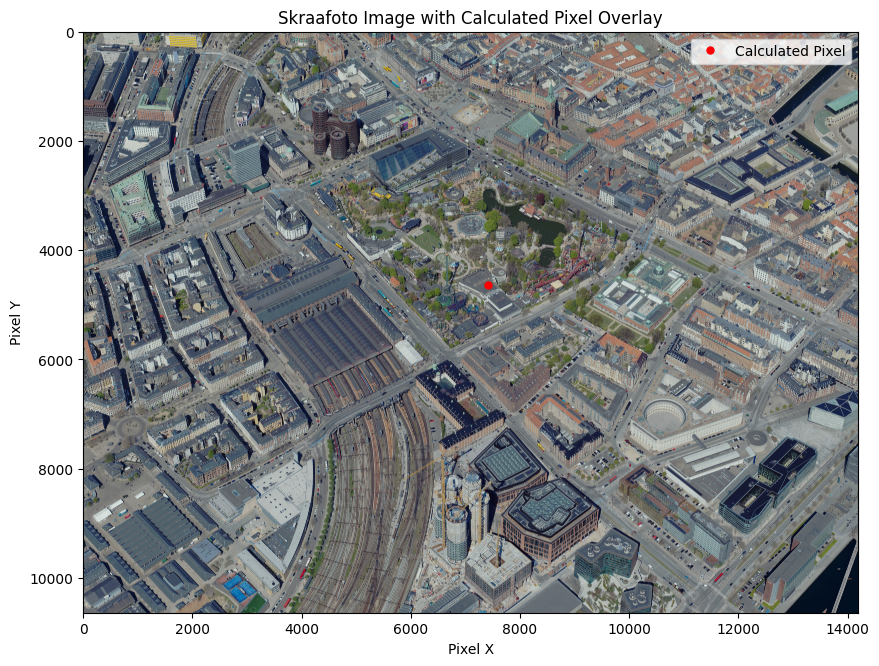

In [150]:
response = requests.get(image_url)
with open("skraafoto_image.tif", "wb") as f:
    f.write(response.content)

# Open the image
image = Image.open("skraafoto_image.tif")

# Display the image with matplotlib
plt.figure(figsize=(10, 10))
plt.imshow(image)


pixel_x = projected_2D_point_final[0]  
pixel_y = image.height - projected_2D_point_final[1]  

# Plot the pixel as a red dot
plt.plot(pixel_x, pixel_y, 'ro', markersize=5, label='Calculated Pixel')
plt.legend()
plt.title("Skraafoto Image with Calculated Pixel Overlay")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.show()

UTM Coordinates (X, Y): 594372.2379962287 6398784.631431146 10


In [151]:
## 2023_81_10_2_0066_00134553

item4 = requests.get('https://api.dataforsyningen.dk/rest/skraafoto_api/v1.0/collections/skraafotos2023/items/2023_81_10_2_0066_00134553', headers=headers)
item4.json()

{'type': 'Feature',
 'stac_version': '1.0.0',
 'stac_extensions': ['https://stac-extensions.github.io/view/v1.0.0/schema.json',
  'https://stac-extensions.github.io/projection/v1.0.0/schema.json',
  'https://raw.githubusercontent.com/stac-extensions/perspective-imagery/main/json-schema/schema.json'],
 'id': '2023_81_10_2_0066_00134553',
 'collection': 'skraafotos2023',
 'geometry': {'type': 'Polygon',
  'coordinates': [[[10.595696318167281, 57.712634314311934],
    [10.57913007449704, 57.712843656987694],
    [10.576052669047254, 57.724308558431446],
    [10.599818278118583, 57.72403261014806],
    [10.595696318167281, 57.712634314311934]]]},
 'bbox': [10.576052669047254,
  57.712634314311934,
  10.599818278118583,
  57.724308558431446],
 'properties': {'datetime': '2023-04-02T13:45:53Z',
  'gsd': 0.1,
  'license': 'various',
  'platform': 'Fixed-wing aircraft',
  'instruments': ['CityMapper2_96773_S150160-112087'],
  'providers': [{'name': 'leica', 'roles': ['producer']},
   {'url': '

In [152]:
data = item4.json()
props = data["properties"]
m11, m12, m13, m21, m22, m23, m31, m32, m33 = props["pers:rotation_matrix"]
Xc, Yc, Zc = props["pers:perspective_center"] ## camera position 
f_mm = props["pers:interior_orientation"]["focal_length"]
ppo_x, ppo_y = props["pers:interior_orientation"]["principal_point_offset"]
pixel_size = props["pers:interior_orientation"]["pixel_spacing"][0]
sensor_cols, sensor_rows = props["pers:interior_orientation"]["sensor_array_dimensions"]

## for coordinate conversion
crs = props["pers:crs"]
vertical_crs = props["pers:vertical_crs"]
image_url = props["asset:data"]

# Calculated values. In pixels. Origo in image lower left.
f = f_mm / pixel_size
x0 = sensor_cols * 0.5 + ppo_x / pixel_size
y0 = sensor_rows * 0.5 + ppo_y / pixel_size

In [8]:
## skagen kirke 
## 57.72129140550318, 10.584370107128134 


latitude = 57.72129140550318
longitude =10.584370107128134 

transformer = Transformer.from_crs("EPSG:4326", "EPSG:" + str(crs), always_xy=True)

x, y = transformer.transform(longitude, latitude)

## https://services.datafordeler.dk/DHMTerraen/DHMKoter/1.0.0/GEOREST/HentKoter?username=xxxx&password=yyyy&geop=POINT(722125.86 6178892.29)
z = getHeightForPoint(x,y)
print("UTM Coordinates (X, Y):", x, y, z)

NameError: name 'Transformer' is not defined

In [154]:
# rotation matrix
R = Matrix([[m11, m12, m13],
              [m21, m22, m23],
              [m31, m32, m33]])

# camera positiom 
C = Matrix([Xc, Yc, Zc])

K = Matrix([[-f, 0, x0,], [0,-f,y0], [0,0,1]]) 

I = eye(3)

translation = Matrix([[-Xc], [-Yc], [-Zc]])

T = Matrix.hstack(I, translation)

In [155]:
KRT = K * R * T 
KRT

Matrix([
[   -29794.6669678503,  -4996.87675060539,  4994.15367404595, 49669660337.6912],
[   -8.57435654893792,   -24812.516787373, -17318.2172599428, 158751527343.714],
[-0.00104981535223876, -0.707598145978715, 0.706614294856261, 4525648.43830459]])

In [156]:
point_3D = Matrix([x, y, z, 1]) ## tivoli
point_3D 

Matrix([
[594372.237996229],
[6398784.63143115],
[       2.4903915],
[               1]])

In [157]:
mapping = KRT * point_3D
mapping

Matrix([
[-13388267.8738556],
[-23563231.0883484],
[-2741.92476734426]])

In [158]:
pixel_x = mapping[0]/mapping[2]
pixel_y = mapping[1]/mapping[2]

pixel_x, pixel_y

(4882.79913194812, 8593.68257254228)

In [159]:
projected_2D_point_final = Matrix([[pixel_x],[pixel_y]])
projected_2D_point_final

Matrix([
[4882.79913194812],
[8593.68257254228]])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/PIL/Image.py:3368: DecompressionBombWarning: Image size (151002880 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


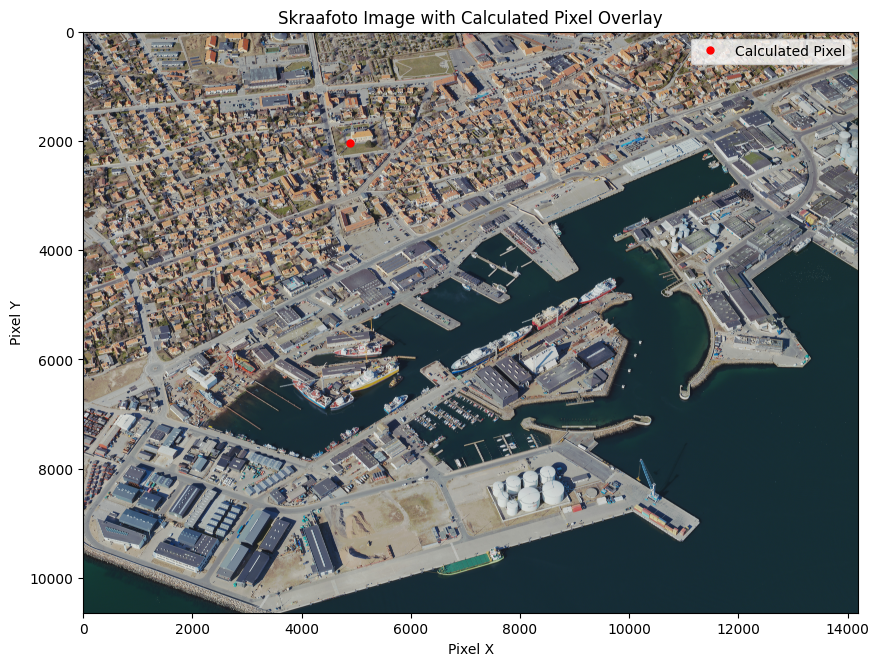

In [160]:
response = requests.get(image_url)
with open("skraafoto_image.tif", "wb") as f:
    f.write(response.content)

# Open the image
image = Image.open("skraafoto_image.tif")

# Display the image with matplotlib
plt.figure(figsize=(10, 10))
plt.imshow(image)


pixel_x = projected_2D_point_final[0]  
pixel_y = image.height - projected_2D_point_final[1]  

# Plot the pixel as a red dot
plt.plot(pixel_x, pixel_y, 'ro', markersize=5, label='Calculated Pixel')
plt.legend()
plt.title("Skraafoto Image with Calculated Pixel Overlay")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.show()

In [157]:
import cv2
image_points = np.array([
    [4651.76610717894, 6185.19050323968],
    [7714.73056629945, 6792.34203020716], 
    [7414.05103238565, 6067.09992155020],
    [4878.56249093926, 8657.86927917554] 
], dtype=np.float32)


real_world_points = np.array([
    [552390.5265647754, 6191179.721881729],
    [573131.7837502563, 6223648.495853622], 
    [724398.3255797952, 6175443.928913474],  
    [594372.2379962287, 6398784.631431146]  
], dtype=np.float32)

# Compute the homography matrix
H, _ = cv2.findHomography(image_points, real_world_points)
H

array([[-3.81044684e+01, -4.63722832e+01,  5.59158836e+05],
       [-4.22316532e+02, -5.15127042e+02,  6.21637980e+06],
       [-6.81911335e-05, -8.25614506e-05,  1.00000000e+00]])

In [158]:
image_point = np.array([[pixel_x, pixel_y, 1]], dtype=np.float32).T  # Add homogeneous coordinate
real_world_point = H @ image_point
real_world_point /= real_world_point[2]  # Normalize by the homogeneous coordinate
print("Real-world coordinates:", real_world_point[:2])

Real-world coordinates: [[ 558587.11801295]
 [6224283.96522124]]


In [161]:
transformer = Transformer.from_crs("EPSG:" + str(crs),"EPSG:4326", always_xy=True)

x, y = transformer.transform(real_world_point[0], real_world_point[1])
print("UTM Coordinates (X, Y):", x, y)

UTM Coordinates (X, Y): [9.9432967] [56.15996394]


In [4]:
user = "RJNTMWOSDL"
password = "BachelorProject123!"

In [58]:
height_model_response

<Response [200]>

In [59]:
height_model_response.json()

{'HentKoterRespons': {'georef': 'EPSG:25832',
  'elevationmodel': 'dtm',
  'data': [{'geop': '722125.86,6178892.29', 'kote': 7.9630218}]}}

In [13]:
from pyproj import Transformer

transformer = Transformer.from_crs("EPSG:4326", "EPSG:" + str(crs), always_xy=True)
x, y = transformer.transform(9.80129254543092,55.874607229954854)

In [14]:
z = getHeightForPoint(x,y)

In [15]:
z

28.204056